<center><h1>HW6</h1></center>

Name: Minhao Zou
<br>
Github Username: zmh0917
<br>
USC ID: 6793831877

## 1. Tree-Based Methods

Import packages

In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from itertools import combinations
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.preprocessing import StandardScaler

### (a) Download the APS Failure data

In [2]:
data_dir = Path("data")
train_data = pd.read_csv(
    data_dir / "aps_failure_training_set.csv",
    skiprows=20,
    na_values="na"
)
test_data = pd.read_csv(
    data_dir / "aps_failure_test_set.csv",
    skiprows=20,
    na_values="na"
)
print(train_data.shape)
print(test_data.shape)
train_data.head()

(60000, 171)
(16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

In [3]:
X_train = train_data.drop(columns="class")
X_test = test_data.drop(columns="class")
y_train = train_data["class"].map({"neg": 0, "pos": 1})
y_test = test_data["class"].map({"neg": 0, "pos": 1})
print(X_train.dropna().shape[0])

train_medians = X_train.median()
test_medians = X_test.median()
X_train_imp = X_train.fillna(train_medians)
X_test_imp = X_test.fillna(test_medians)

missing_sum = pd.DataFrame({
    "Before": [X_train.isna().sum().sum(),X_test.isna().sum().sum()],
    "After": [X_train_imp.isna().sum().sum(),X_test_imp.isna().sum().sum()]
},
index=["Train", "Test"]
)
display(missing_sum)

591


,Before,After
Train,850015,0
Test,228680,0


Common imputation techniques include mean or median imputation, most-frequent imputation, k-nearest-neighbor imputation, and iterative model-based imputation. use column-wise median imputation because it's simple, computationally inexpensive, and less sensitive to extreme values than mean imputation. Only 591 of the 60,000 training observations have no missing values, so deleting all incomplete observations would discard most of the training data.

#### (ii) Calculate the coefficient of variation

In [4]:
feature_means = X_train_imp.mean()
feature_stds = X_train_imp.std(ddof=1)
cv_values = feature_stds / feature_means.replace(0, np.nan)

cv_table = pd.DataFrame({
    "mean": feature_means,
    "sample SD": feature_stds,
    "CV": cv_values
}).sort_values("CV", ascending=False)
print("feature Num:", len(cv_table))
display(cv_table.head(13).round(4))

feature Num: 170


,mean,sample SD,CV
cf_000,143107.5341,3.504525e+07,244.8875
co_000,143330.0177,3.504525e+07,244.5074
ad_000,143438.2921,3.504525e+07,244.3228
cs_009,770.5097,1.833278e+05,237.9306
dh_000,4392.6408,5.412441e+05,123.2161
dj_000,37.2713,4.379166e+03,117.4942
ag_000,219.1577,2.036364e+04,92.9178
as_000,125.4079,1.095219e+04,87.3325
ay_009,1149.6196,9.741156e+04,84.7337
ak_000,907.6607,7.299859e+04,80.4250


#### (iii) Plot a correlation matrix

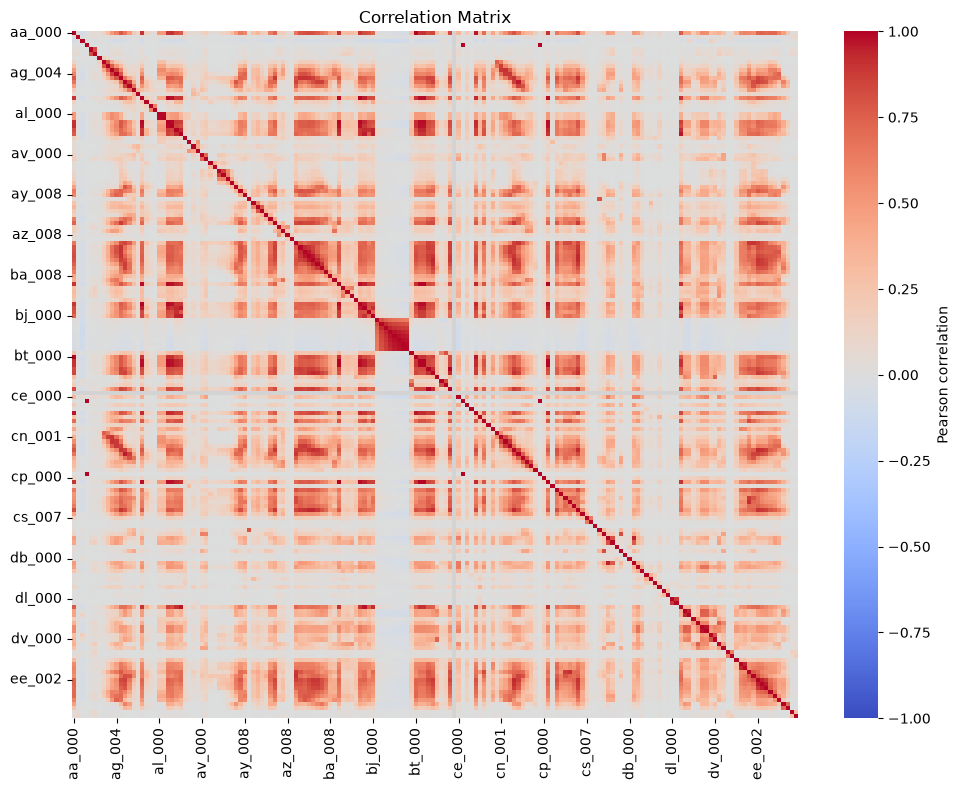

In [5]:
corr_matrix = X_train_imp.corr()
plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    corr_matrix,
    mask=corr_matrix.isna(),
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=10,
    yticklabels=10,
    cbar_kws={"label": "Pearson correlation"}
)
ax.set_facecolor("lightgray")
plt.title("Correlation Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
# GPT assist with plotting

#### (iv) Make scatter plots and box plots

Selected features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


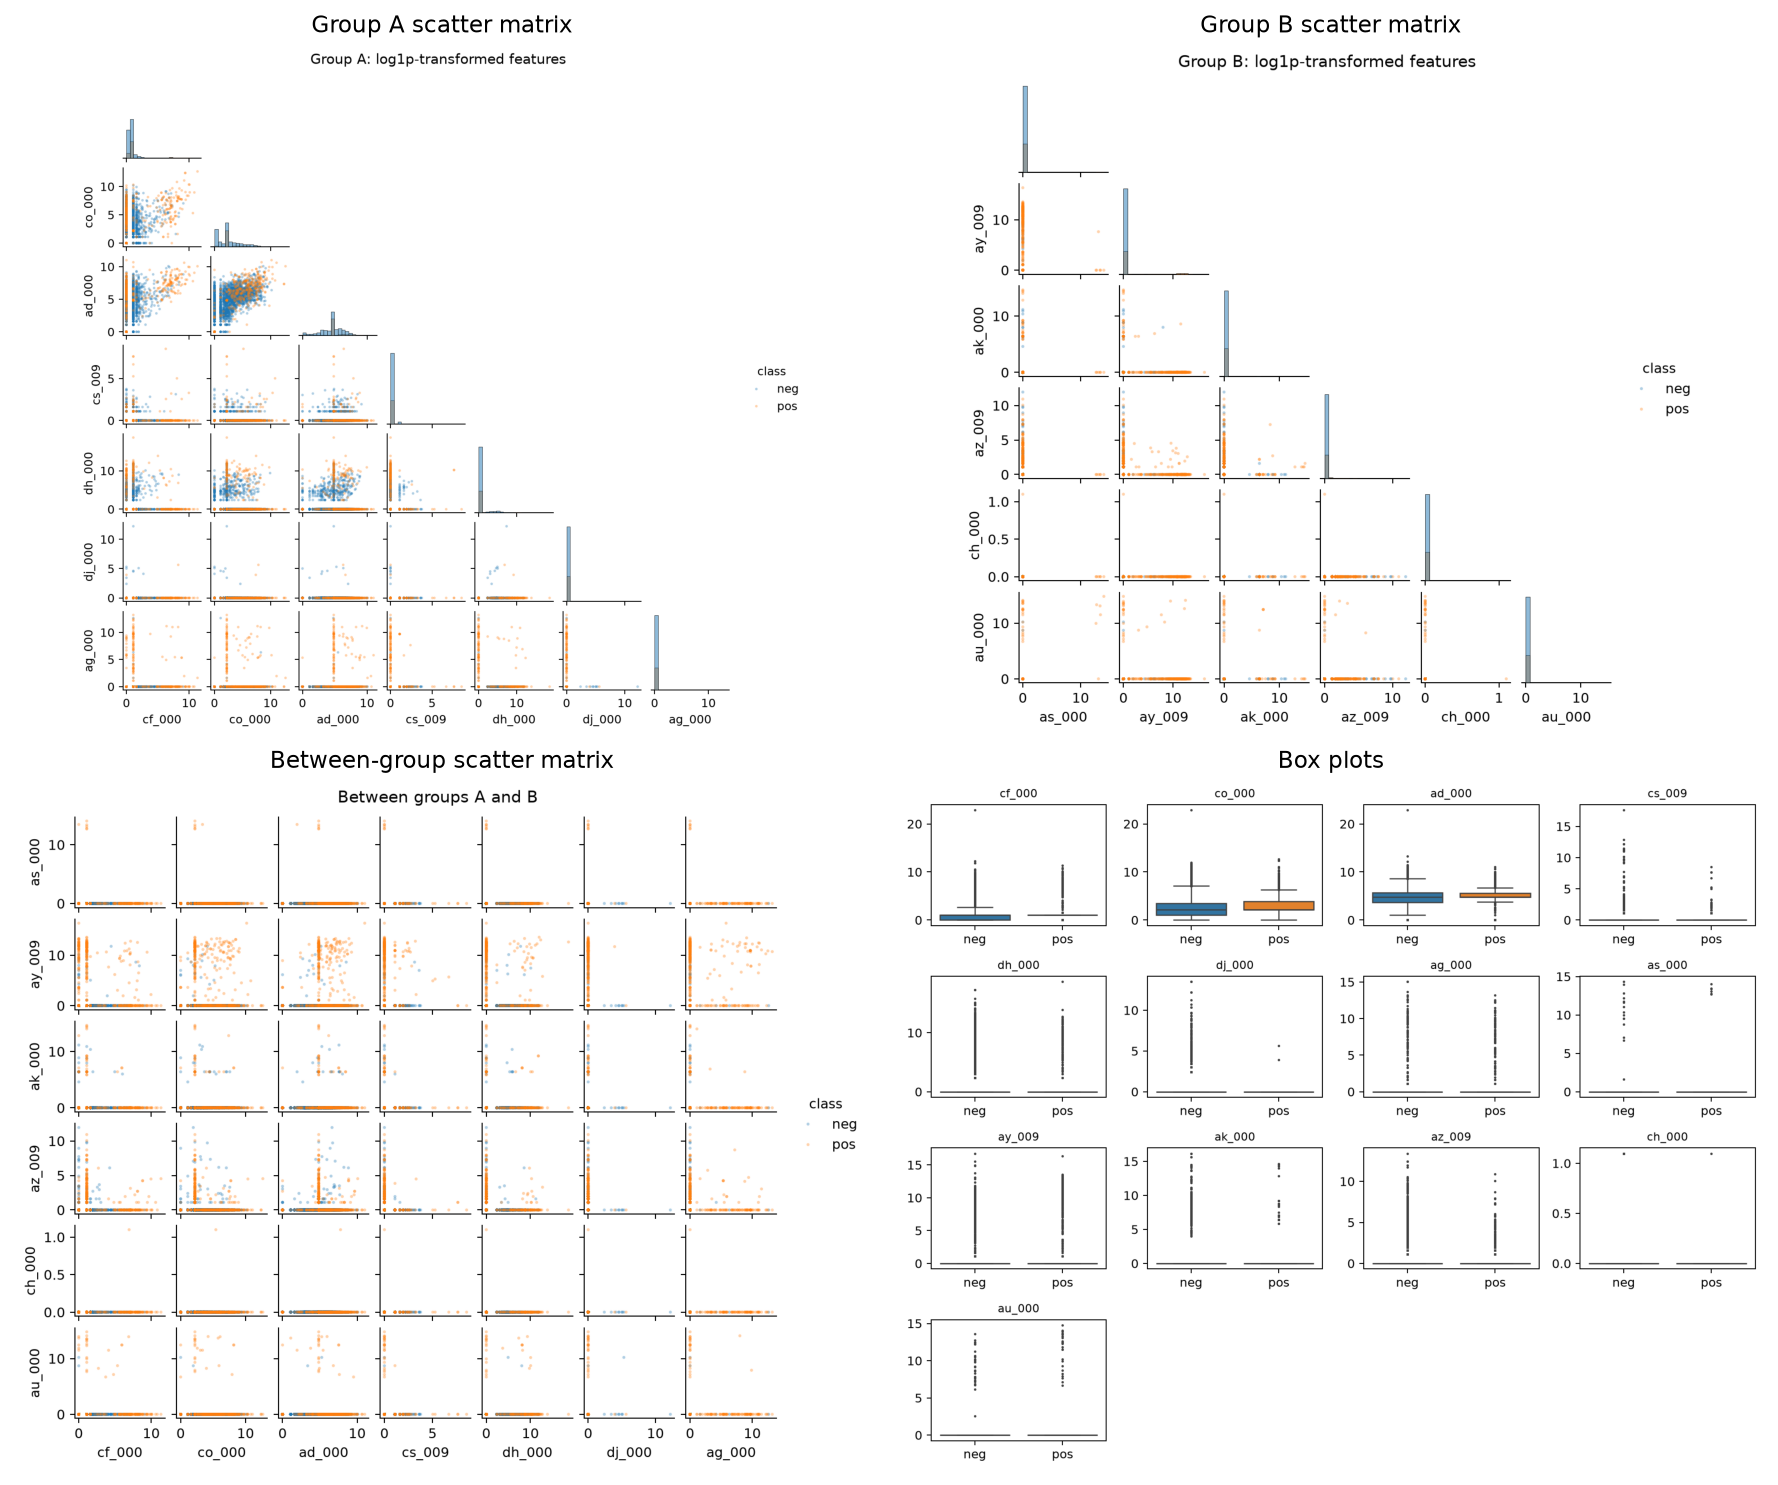

In [ ]:
# GPT helped with the plotting and adjusted the figure formatting to save space.
k = int(np.sqrt(X_train_imp.shape[1]))
top_features = cv_table.head(k).index.tolist()
print("selected:", top_features)
plot_data = np.log1p(X_train_imp[top_features]).copy()
plot_data["class"] = train_data["class"]

scatter_data = pd.concat([
    plot_data.loc[plot_data["class"] == "neg"].sample(n=3000,random_state=42),
    plot_data.loc[plot_data["class"] == "pos"]
])

group_a = top_features[:7]
group_b = top_features[7:]
fig_dir = Path("figures")
fig_dir.mkdir(exist_ok=True)
g = sns.pairplot(data=scatter_data,vars=group_a,hue="class",hue_order=["neg", "pos"],corner=True,diag_kind="hist",height=1.15,plot_kws={"s": 5, "alpha": 0.35, "linewidth": 0},diag_kws={"bins": 20})
g.figure.suptitle("Group A: log1p-transformed features", y=1.02)
group_a_path = fig_dir / "group_a_pairplot.png"
g.figure.savefig(group_a_path, dpi=180, bbox_inches="tight")
plt.close(g.figure)

g = sns.pairplot(data=scatter_data,vars=group_b,hue="class",hue_order=["neg", "pos"],corner=True,diag_kind="hist",height=1.15,plot_kws={"s": 5, "alpha": 0.35, "linewidth": 0},diag_kws={"bins": 20})
g.figure.suptitle("Group B: log1p-transformed features", y=1.02)
group_b_path = fig_dir / "group_b_pairplot.png"
g.figure.savefig(group_b_path, dpi=180, bbox_inches="tight")
plt.close(g.figure)

g = sns.pairplot(data=scatter_data,x_vars=group_a,y_vars=group_b,hue="class",hue_order=["neg", "pos"], diag_kind=None,height=1.15,plot_kws={"s": 5, "alpha": 0.35, "linewidth": 0})
g.figure.suptitle("Between groups A and B", y=1.02)
between_path = fig_dir / "between_groups_pairplot.png"
g.figure.savefig(between_path, dpi=180, bbox_inches="tight")
plt.close(g.figure)

fig, axes = plt.subplots(4, 4, figsize=(10, 8))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=plot_data,x="class",y=feature,order=["neg", "pos"],hue="class",legend=False,fliersize=1,ax=ax)
    ax.set_title(feature, fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")

for ax in axes.flat[len(top_features):]:
    ax.set_visible(False)
plt.tight_layout()
boxplot_path = fig_dir / "boxplots.png"
fig.savefig(boxplot_path, dpi=180, bbox_inches="tight")
plt.close(fig)

combined_paths = [group_a_path,group_b_path,between_path,boxplot_path]
combined_titles = ["Group A scatter matrix","Group B scatter matrix","Between-group scatter matrix","Box plots"]
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=150)
for ax, path, title in zip(axes.flat, combined_paths, combined_titles):
    img = plt.imread(path)
    ax.imshow(img)
    ax.set_title(title, fontsize=11)
    ax.axis("off")

plt.tight_layout()
plt.show()

The plots show considerable overlap between classes, many zero values, and long-tailed distributions. However, statistical significance cannot be determined from scatter plots alone. A high CV only indicates greater relative variability. Overlapping class distributions also don't necessarily mean that a feature is irrelevant, since it may still contribute through nonlinear relationships or interactions with other features.

#### (v) Is this data set imbalanced?

In [6]:
class_counts = pd.DataFrame({
    "Train": train_data["class"].value_counts(),
    "Test": test_data["class"].value_counts()
}).reindex(["neg", "pos"])

display(class_counts)
print(f"train positive: {y_train.mean():.4%}")
print(f"test positive: {y_test.mean():.4%}")

negative_positive_ratio = (class_counts.loc["neg", "Train"]/class_counts.loc["pos", "Train"])
print(f"train neg-to-pos ratio: "f"{negative_positive_ratio:.0f}:1")

,Train,Test
class,,
neg,59000,15625
pos,1000,375


train positive: 1.6667%
test positive: 2.3438%
train neg-to-pos ratio: 59:1


The training set contains 59,000 negative observations and 1,000 positive observations, giving a negative-to-positive ratio of 59:1. Positive observations account for approximately 1.67% of the training set.

The test set contains 15,625 negative observations and 375 positive observations, with a positive proportion of approximately 2.34%.

Therefore, the dataset is severely imbalanced, with the positive class being the minority class. Accuracy alone may be misleading: a classifier that always predicts the negative class would achieve approximately 98.33% accuracy on the training set while failing to identify any positive observations.

### (c) Train a random forest

In [7]:
rf = RandomForestClassifier(
    n_estimators=100,
    class_weight=None,
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train_imp, y_train)
train_pred = rf.predict(X_train_imp)
test_pred = rf.predict(X_test_imp)
train_prob = rf.predict_proba(X_train_imp)[:, 1]
test_prob = rf.predict_proba(X_test_imp)[:, 1]
train_cm = confusion_matrix(y_train, train_pred)
test_cm = confusion_matrix(y_test, test_pred)
train_auc = roc_auc_score(y_train, train_prob)
test_auc = roc_auc_score(y_test, test_prob)
train_error = 1-accuracy_score(y_train, train_pred)
test_error = 1-accuracy_score(y_test, test_pred)
oob_error = 1-rf.oob_score_
rf_results = pd.DataFrame({
    "AUC": [train_auc, test_auc],
    "Misclassification Rate": [train_error, test_error]
},index=["Train", "Test"])
display(rf_results.round(6))
print(f"OOB err: {oob_error:.6f}")
print(f"test err: {test_error:.6f}")

,AUC,Misclassification Rate
Train,1.000000,0.000017
Test,0.992756,0.007563


OOB err: 0.006167
test err: 0.007563


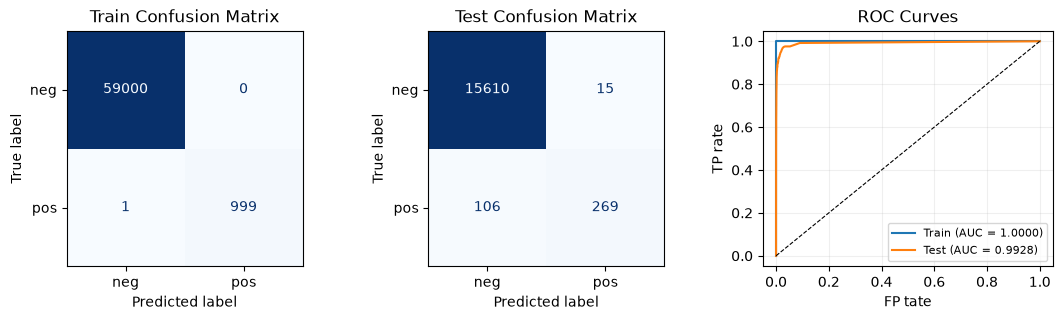

In [ ]:
# plotting assist by GPT
train_fpr, train_tpr, _ = roc_curve(y_train, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ConfusionMatrixDisplay(
    confusion_matrix=train_cm,
    display_labels=["neg", "pos"]
).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Train Confusion Matrix")
ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=["neg", "pos"]
).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("Test Confusion Matrix")
axes[2].plot(train_fpr, train_tpr,label=f"Train (AUC = {train_auc:.4f})")
axes[2].plot(test_fpr, test_tpr,label=f"Test (AUC = {test_auc:.4f})")
axes[2].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[2].set_xlabel("FP tate")
axes[2].set_ylabel("TP rate")
axes[2].set_title("ROC Curves")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

training AUC 1.0000 and test AUC 0.9928, misclassification rates0.0017% and 0.7563%

OOB error 0.6167% is close to the test error 0.7563%, suggest that OOB provides reasonable estimate of test error

still misclassifies 106 out of 375 positive test samples, the class imbalance remains a concern

### (d) Research class imbalance in random forest

,Train AUC,Test AUC,Train Error,Test Error,OOB Error,Test FN
Unweighted,1.0,0.992756,0.000017,0.007563,0.006167,106
Balanced,1.0,0.990378,0.000017,0.011437,0.008017,164


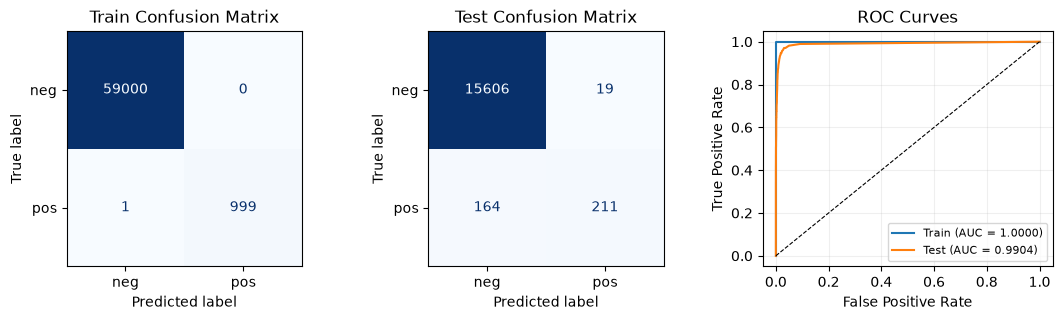

In [10]:
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    bootstrap=True,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf_balanced.fit(X_train_imp, y_train)
bal_train_pred = rf_balanced.predict(X_train_imp)
bal_test_pred = rf_balanced.predict(X_test_imp)
bal_train_prob = rf_balanced.predict_proba(X_train_imp)[:, 1]
bal_test_prob = rf_balanced.predict_proba(X_test_imp)[:, 1]

bal_train_cm = confusion_matrix(y_train, bal_train_pred)
bal_test_cm = confusion_matrix(y_test, bal_test_pred)
bal_train_auc = roc_auc_score(y_train, bal_train_prob)
bal_test_auc = roc_auc_score(y_test, bal_test_prob)
bal_train_error = 1 - accuracy_score(y_train, bal_train_pred)
bal_test_error = 1 - accuracy_score(y_test, bal_test_pred)
bal_oob_error = 1 - rf_balanced.oob_score_
rf_comparison = pd.DataFrame({
    "Train AUC": [train_auc, bal_train_auc],
    "Test AUC": [test_auc, bal_test_auc],
    "Train Error": [train_error, bal_train_error],
    "Test Error": [test_error, bal_test_error],
    "OOB Error": [oob_error, bal_oob_error],
    "Test FN": [test_cm[1, 0], bal_test_cm[1, 0]]
},index=["Unweighted", "Balanced"])
display(rf_comparison.round(6))
# plotting assist by GPT
bal_train_fpr, bal_train_tpr, _ = roc_curve(y_train, bal_train_prob)
bal_test_fpr, bal_test_tpr, _ = roc_curve(y_test, bal_test_prob)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ConfusionMatrixDisplay(confusion_matrix=bal_train_cm,display_labels=["neg", "pos"]).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Train Confusion Matrix")
ConfusionMatrixDisplay(confusion_matrix=bal_test_cm,display_labels=["neg", "pos"]).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("Test Confusion Matrix")
axes[2].plot(bal_train_fpr, bal_train_tpr,label=f"Train (AUC = {bal_train_auc:.4f})")
axes[2].plot(bal_test_fpr, bal_test_tpr,label=f"Test (AUC = {bal_test_auc:.4f})")
axes[2].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("ROC Curves")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

Compared with the unweighted, the test error increases from 0.7563% to 1.1438%, while the test AUC decreases from 0.9928 to 0.9904. The OOB error also increases from 0.6167% to 0.8017%. The number of false negatives increases from 106 to 164. class weighting does not improve model　performance.

### (e) XGBoost and Model Trees

,Alpha,CV AUC,CV Error
3,10.00,0.989449,0.007500
1,0.10,0.989233,0.006400
0,0.01,0.988903,0.006467
2,1.00,0.988250,0.006483
4,100.00,0.981518,0.011067


Best alpha: 10
5-fold CV AUC: 0.989449
5-fold CV Error: 0.007500


,AUC,Misclassification Rate
Train,0.996065,0.004383
Test,0.995295,0.008563


CV Error: 0.007500
Test Error: 0.008563


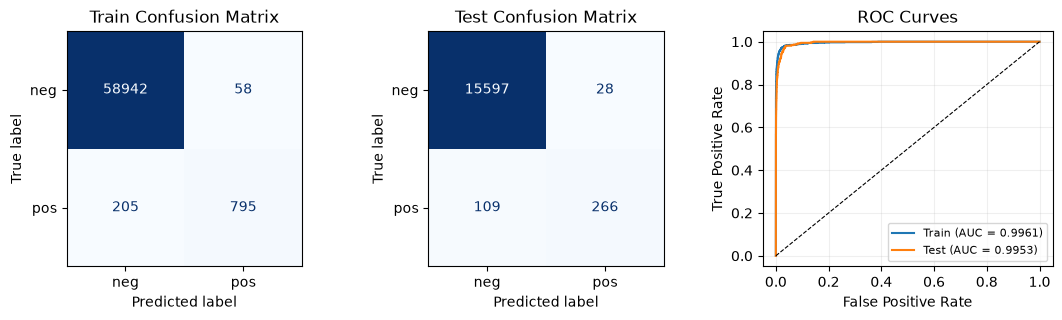

In [ ]:
xgb_params = {
    "n_estimators": 100,
    "max_depth": 4,
    "learning_rate": 0.1,
    "booster": "gbtree",
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "scale_pos_weight": 1,
    "random_state": 42,
    "n_jobs": -1
}
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(**xgb_params))
])
# Cross-validation assisted by GPT
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
xgb_search = GridSearchCV(
    xgb_pipeline,
    param_grid={"xgb__reg_alpha": [0.01, 0.1, 1, 10, 100]},
    scoring={"auc": "roc_auc", "accuracy": "accuracy"},
    refit="auc",
    cv=cv,
    n_jobs=1
)
xgb_search.fit(X_train, y_train)
best_alpha = xgb_search.best_params_["xgb__reg_alpha"]
cv_auc = xgb_search.best_score_
cv_error = 1 - xgb_search.cv_results_["mean_test_accuracy"][xgb_search.best_index_]
cv_results = pd.DataFrame({
    "Alpha": [p["xgb__reg_alpha"] for p in xgb_search.cv_results_["params"]],
    "CV AUC": xgb_search.cv_results_["mean_test_auc"],
    "CV Error": 1 - xgb_search.cv_results_["mean_test_accuracy"]
}).sort_values("CV AUC", ascending=False)

display(cv_results.round(6))
print(f"Best alpha: {best_alpha}")
print(f"5-fold CV AUC: {cv_auc:.6f}")
print(f"5-fold CV Error: {cv_error:.6f}")

xgb_model = XGBClassifier(**xgb_params, reg_alpha=best_alpha)
xgb_model.fit(X_train_imp, y_train)
xgb_train_pred = xgb_model.predict(X_train_imp)
xgb_test_pred = xgb_model.predict(X_test_imp)
xgb_train_prob = xgb_model.predict_proba(X_train_imp)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test_imp)[:, 1]
xgb_train_cm = confusion_matrix(y_train, xgb_train_pred)
xgb_test_cm = confusion_matrix(y_test, xgb_test_pred)
xgb_train_auc = roc_auc_score(y_train, xgb_train_prob)
xgb_test_auc = roc_auc_score(y_test, xgb_test_prob)
xgb_train_error = 1-accuracy_score(y_train, xgb_train_pred)
xgb_test_error = 1-accuracy_score(y_test, xgb_test_pred)
xgb_results = pd.DataFrame({
    "AUC": [xgb_train_auc, xgb_test_auc],
    "Misclassification Rate": [xgb_train_error, xgb_test_error]
}, index=["Train", "Test"])

display(xgb_results.round(6))
print(f"CV Error: {cv_error:.6f}")
print(f"Test Error: {xgb_test_error:.6f}")

# Plotting assisted by GPT
xgb_train_fpr, xgb_train_tpr, _ = roc_curve(y_train, xgb_train_prob)
xgb_test_fpr, xgb_test_tpr, _ = roc_curve(y_test, xgb_test_prob)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ConfusionMatrixDisplay(
    confusion_matrix=xgb_train_cm,
    display_labels=["neg", "pos"]
).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Train Confusion Matrix")
ConfusionMatrixDisplay(
    confusion_matrix=xgb_test_cm,
    display_labels=["neg", "pos"]
).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("Test Confusion Matrix")
axes[2].plot(
    xgb_train_fpr, xgb_train_tpr,
    label=f"Train (AUC = {xgb_train_auc:.4f})"
)
axes[2].plot(
    xgb_test_fpr, xgb_test_tpr,
    label=f"Test (AUC = {xgb_test_auc:.4f})"
)
axes[2].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[2].set_xlabel("FP rate")
axes[2].set_ylabel("TP rate")
axes[2].set_title("ROC Curves")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

Five-fold stratified cross-validation selected alpha = 10, with mean CV AUC 0.9894.

CV error 0.7500%, which is close to the test error 0.8563%. The training and test AUCs are 0.9961 and 0.9953, respectively, indicating good classification performance.

However, the model still misses 109 of the 375 positive test samples, suggest class imbalance.

### (f) Use SMOTE to pre-process your data

,Alpha,CV AUC,CV Error
4,100.00,0.986483,0.023233
2,1.00,0.986032,0.017017
3,10.00,0.986018,0.018100
1,0.10,0.985823,0.016767
0,0.01,0.985199,0.016650


Best alpha: 100
5-fold CV AUC: 0.986483
5-fold CV Error: 0.023233


,AUC,Misclassification Rate
Train,0.994530,0.022033
Test,0.993701,0.024813


,CV Error,Test Error,Test AUC,Test FP,Test FN
No SMOTE,0.007500,0.008563,0.995295,28,109
SMOTE,0.023233,0.024813,0.993701,371,26


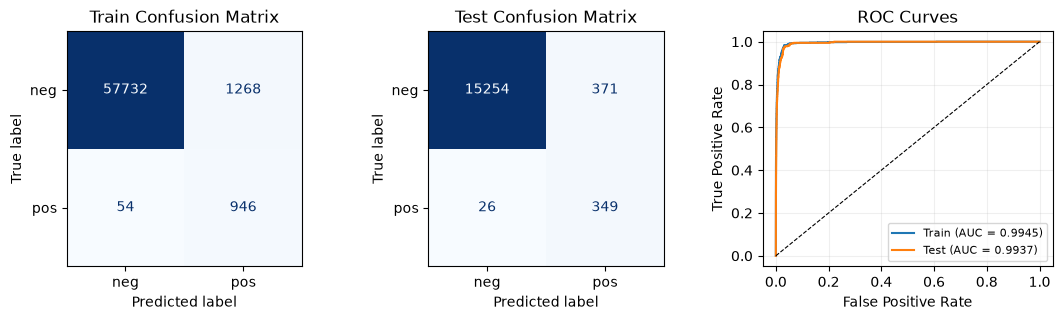

In [ ]:
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(**xgb_params))
])
smote_search = GridSearchCV(
    smote_pipeline,
    param_grid={"xgb__reg_alpha": [0.01, 0.1, 1, 10, 100]},
    scoring={"auc": "roc_auc", "accuracy": "accuracy"},
    refit="auc",
    cv=cv,
    n_jobs=1
)
smote_search.fit(X_train, y_train)
smote_alpha = smote_search.best_params_["xgb__reg_alpha"]
smote_cv_auc = smote_search.best_score_
smote_cv_error = 1 - smote_search.cv_results_["mean_test_accuracy"][
    smote_search.best_index_
]
smote_cv_results = pd.DataFrame({
    "Alpha": [
        p["xgb__reg_alpha"] for p in smote_search.cv_results_["params"]
    ],
    "CV AUC": smote_search.cv_results_["mean_test_auc"],
    "CV Error": 1 - smote_search.cv_results_["mean_test_accuracy"]
}).sort_values("CV AUC", ascending=False)
# SMOTE setup assisted by GPT
display(smote_cv_results.round(6))
print(f"Best alpha: {smote_alpha}")
print(f"5-fold CV AUC: {smote_cv_auc:.6f}")
print(f"5-fold CV Error: {smote_cv_error:.6f}")

smote_model = smote_search.best_estimator_
smote_train_pred = smote_model.predict(X_train)
smote_test_pred = smote_model.predict(X_test_imp)
smote_train_prob = smote_model.predict_proba(X_train)[:, 1]
smote_test_prob = smote_model.predict_proba(X_test_imp)[:, 1]

smote_train_cm = confusion_matrix(y_train, smote_train_pred)
smote_test_cm = confusion_matrix(y_test, smote_test_pred)
smote_train_auc = roc_auc_score(y_train, smote_train_prob)
smote_test_auc = roc_auc_score(y_test, smote_test_prob)
smote_train_error = 1-accuracy_score(y_train, smote_train_pred)
smote_test_error = 1-accuracy_score(y_test, smote_test_pred)

smote_results = pd.DataFrame({
    "AUC": [smote_train_auc, smote_test_auc],
    "Misclassification Rate": [smote_train_error, smote_test_error]
}, index=["Train", "Test"])
display(smote_results.round(6))

xgb_comparison = pd.DataFrame({
    "CV Error": [cv_error, smote_cv_error],
    "Test Error": [xgb_test_error, smote_test_error],
    "Test AUC": [xgb_test_auc, smote_test_auc],
    "Test FP": [xgb_test_cm[0, 1], smote_test_cm[0, 1]],
    "Test FN": [xgb_test_cm[1, 0], smote_test_cm[1, 0]]
}, index=["No SMOTE", "SMOTE"])
display(xgb_comparison.round(6))

smote_train_fpr, smote_train_tpr, _ = roc_curve(y_train, smote_train_prob)
smote_test_fpr, smote_test_tpr, _ = roc_curve(y_test, smote_test_prob)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
ConfusionMatrixDisplay(
    confusion_matrix=smote_train_cm,
    display_labels=["neg", "pos"]
).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
axes[0].set_title("Train Confusion Matrix")
ConfusionMatrixDisplay(
    confusion_matrix=smote_test_cm,
    display_labels=["neg", "pos"]
).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format="d")
axes[1].set_title("Test Confusion Matrix")
axes[2].plot(smote_train_fpr, smote_train_tpr,label=f"Train (AUC = {smote_train_auc:.4f})")
axes[2].plot(smote_test_fpr, smote_test_tpr,label=f"Test (AUC = {smote_test_auc:.4f})")
axes[2].plot([0, 1], [0, 1], "k--", linewidth=0.8)
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate")
axes[2].set_title("ROC Curves")
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.2)

plt.tight_layout()
plt.show()

best regularization parameter alpha = 100, with CV AUC 0.9865.

CV error 2.3233%, close to test error 2.4813%. Compared with model without SMOTE, test AUC slightly decreases from 0.9953 to 0.9937, while test error increases from 0.8563% to 2.4813%.

SMOTE reduces false negatives from 109 to 26, while false positives increase from 28 to 371. SMOTE improves minority-class recall at the cost of more false positives and a higher overall error rate.

## 2. ISLR 6.6.3

(a) (iv)Steadily decrease. s increases, the constraint becomes less restrictive, so the minimum training RSS cannot increase.

(b) (ii)Decrease initially, then increase. Increasing s reduces underfitting at first, but excessive flexibility may lead to overfitting, giving a typical U-shaped test RSS.

(c) (iii)Steadily increase. larger s allows more flexible model, which is generally more sensitive to changes in the training data.

(d) (iv)Steadily decrease.constraint becomes less restrictive, model can better capture underlying relationship, reducing squared bias.

(e) (v)Remain constant. Irreducible error comes from inherent noise in the data and does not depend on s.

## 3. ISLR 6.6.5 & 4. ISLR 8.4.5

![6.6.5 & 8.4.5](figures/solution23.jpg)

## 5. ISLR 9.7.3

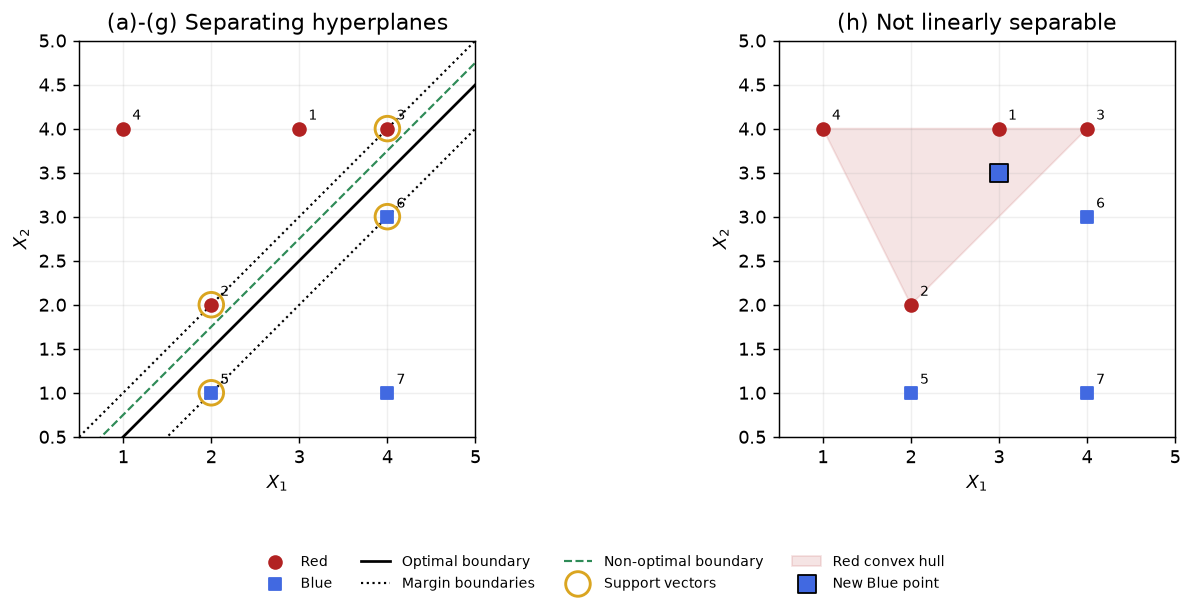

In [ ]:
# Plotting assisted by ChatGPT
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])
support = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
x = np.linspace(0.5, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.7), dpi=130)
for ax in axes:
    ax.scatter(red[:, 0], red[:, 1], color="firebrick",s=50, label="Red", zorder=3)
    ax.scatter(blue[:, 0], blue[:, 1], color="royalblue",marker="s", s=50, label="Blue", zorder=3)
    for i, (x1, x2) in enumerate(np.vstack((red, blue)), 1):
        ax.annotate(str(i), (x1, x2), xytext=(5, 5),textcoords="offset points", fontsize=8)
    ax.set(xlim=(0.5, 5), ylim=(0.5, 5),xlabel="$X_1$", ylabel="$X_2$")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
# a-g
axes[0].plot(x, x - 0.5, "k-", label="Optimal boundary")
axes[0].plot(x, x, "k:", linewidth=1.2, label="Margin boundaries")
axes[0].plot(x, x - 1, "k:", linewidth=1.2)
axes[0].plot(x, x - 0.25, "--", color="seagreen",linewidth=1.2, label="Non-optimal boundary")
axes[0].scatter(support[:, 0], support[:, 1], s=185,facecolors="none", edgecolors="goldenrod",linewidths=1.6, zorder=4, label="Support vectors")
axes[0].set_title("(a)-(g) Separating hyperplanes")
# h
red_hull = np.array([[1, 4], [2, 2], [4, 4]])
axes[1].fill(red_hull[:, 0], red_hull[:, 1],color="firebrick", alpha=0.12,label="Red convex hull")
axes[1].scatter(3, 3.5, marker="s", s=95,color="royalblue", edgecolors="black",zorder=5, label="New Blue point")
axes[1].set_title("(h) Not linearly separable")
handles, labels = axes[0].get_legend_handles_labels()
h2, l2 = axes[1].get_legend_handles_labels()
items = dict(zip(labels + l2, handles + h2))
fig.legend(items.values(), items.keys(), loc="lower center",ncol=4, fontsize=8, frameon=False,bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=(0, 0.15, 1, 1))
plt.show()



**(a)** The seven observations are plotted in the figure. The Red and Blue classes are linearly separable.

**(b)** The optimal separating hyperplane lies halfway between the lines $X_2=X_1$ and $X_2=X_1-1$:

$$
\boxed{\frac12-X_1+X_2=0}
$$

**(c)** The classification rule is:

$$
\begin{cases}
\text{Red}, & \frac12-X_1+X_2>0,\\
\text{Blue}, & \text{otherwise}.
\end{cases}
$$

Thus, $\beta_0=0.5$, $\beta_1=-1$, and $\beta_2=1$.

**(d)** The margin boundaries are $X_2=X_1$ and $X_2=X_1-1$. The maximum margin is:

$$
\boxed{M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt2}}
$$

**(e)** The support vectors are observations **2, 3, 5, and 6**, which lie on the margin boundaries.

**(f)** Observation 7 is not a support vector. A small movement of this point will not affect the optimal hyperplane as long as the support vectors remain unchanged.

**(g)** A non-optimal separating hyperplane is:

$$
\boxed{X_2=X_1-\frac14}
$$

It separates the classes but has a smaller margin of $1/(4\sqrt2)$.

**(h)** Add a Blue observation at $(3,3.5)$. This point lies inside the convex hull of the Red observations, so the two classes are no longer linearly separable.

（Handwriting-to-Markdown conversion assisted by ChatGPT）